<p class="hz-kicker">Week 6 · Self-paced lab</p>

# Choosing and explaining a model

Altamar's management wants a decision, not a leaderboard. In this lab you tune a forest and a boosting model, choose a model for each question with reasons beyond accuracy, explain how one input drives it, and draft the pyramid you would present.

<ul class="hz-lesson-meta"><li>≈ 2 hours</li><li>5 tasks</li><li>Runs in your browser</li><li>Graded quiz</li></ul>

**Recap of the live session**

- A **random forest** averages hundreds of trees, each grown on its own bootstrap sample with random inputs: steadier and more accurate than one tree. **Gradient boosting** adds small trees in a row, each fitted to the errors left by the previous ones.
- On the same test bookings, boosting cut the typical rate error from USD 20.5 (line) and USD 13.3 (week 5's tuned tree) to USD 8.4 a night; for cancellations the forest and boosting tie (AUC 0.77, against 0.74 and 0.75).
- **Permutation importance** says which inputs matter; **partial dependence** shows how; both describe patterns, not causes.

Run this cell first. You don't need to read it.

In [1]:
# Run this cell first. You don't need to read it.
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import (RandomForestRegressor, RandomForestClassifier, GradientBoostingRegressor,
                              HistGradientBoostingRegressor, HistGradientBoostingClassifier)
from sklearn.metrics import mean_absolute_error, r2_score, roc_auc_score, roc_curve
from sklearn.inspection import permutation_importance

DATA = "https://raw.githubusercontent.com/hizocar/mba-business-analytics-1/main/docs/datasets/"
df = pd.read_csv(DATA + "altamar_bookings_clean.csv")
df["arrival_month"] = pd.to_datetime(df["arrival_date"]).dt.month
HOTELS = ["Santiago", "Viña del Mar", "Puerto Varas"]
TEXT = ["hotel", "room_type", "customer_type", "channel", "deposit", "country"]
NUMBERS = ["lead_time_days", "nights", "weekend_nights", "adults", "children", "repeat_guest",
           "previous_cancellations", "special_requests", "parking", "arrival_month"]

# The same inputs and train/test splits as in weeks 3 to 5 (25% of bookings kept aside for the test)
X_rate, y_rate = df[NUMBERS + TEXT], df["adr"]
X_cancel, y_cancel = df[NUMBERS + TEXT + ["adr"]], df["canceled"]
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_rate, y_rate, test_size=0.25, random_state=42)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(X_cancel, y_cancel, test_size=0.25, random_state=42, stratify=y_cancel)


def model(estimator, month_as_category=False):
    """Turn the text columns into 0/1 columns (as pd.get_dummies(drop_first=True) did in week 5), then fit `estimator`."""
    text = TEXT + (["arrival_month"] if month_as_category else [])
    encode = make_column_transformer(("passthrough", lambda X: [c for c in X.columns if c not in text]),
                                     (OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), text))
    return make_pipeline(encode, estimator)


def rate_scores(name, m):
    p = m.predict(Xr_test)
    return {"model": name, "typical error (USD)": round(mean_absolute_error(yr_test, p), 1),
            "R²": round(r2_score(yr_test, p), 3)}


def cancel_scores(name, m):
    p = m.predict_proba(Xc_test)[:, 1]
    top150 = np.argsort(-p)[:150]
    return {"model": name, "AUC": round(roc_auc_score(yc_test, p), 3),
            "cancelled, of the 150 riskiest": int(yc_test.values[top150].sum())}


def pd_curve(m, X, column, grid, proba=False):
    """Partial dependence: give every booking in X the same value of `column`, average the predictions."""
    out = []
    for v in grid:
        X_v = X.assign(**{column: v})
        out.append(m.predict_proba(X_v)[:, 1].mean() if proba else m.predict(X_v).mean())
    return np.array(out)


plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"Santiago": "#2b6f78", "Viña del Mar": "#c85a24", "Puerto Varas": "#7a4f8e"}
print(f"{len(df):,} bookings loaded. Training: {len(Xr_train):,} bookings · Test: {len(Xr_test):,} bookings.")

5,964 bookings loaded. Training: 4,473 bookings · Test: 1,491 bookings.


## <span class="hz-step-n">01</span> Task 1 · How many trees, how big the leaves

A forest has two settings that matter most: the **number of trees** (more trees, a steadier average, but slower) and the **minimum bookings per leaf** (small leaves let each tree memorize single bookings; big leaves force broad rules). The cell trains one forest for the nightly rate with your settings and reports its typical error on the training bookings and on the test bookings.

In [2]:
# ✏️ Change these settings
N_TREES = 100
MIN_LEAF = 3

f = model(RandomForestRegressor(n_estimators=N_TREES, min_samples_leaf=MIN_LEAF, random_state=42))
start = time.time()
f.fit(Xr_train, yr_train)
print(f"{N_TREES} trees, at least {MIN_LEAF} bookings per leaf, trained in {time.time() - start:.1f} seconds")
print(f"Typical error on training bookings: USD {mean_absolute_error(yr_train, f.predict(Xr_train)):.1f}")
print(f"Typical error on test bookings:     USD {mean_absolute_error(yr_test, f.predict(Xr_test)):.1f}"
      "   (the line: USD 20.5; week 5's tuned tree: USD 13.3)")

100 trees, at least 3 bookings per leaf, trained in 0.8 seconds
Typical error on training bookings: USD 6.3
Typical error on test bookings:     USD 10.4   (the line: USD 20.5; week 5's tuned tree: USD 13.3)


The cell trains forests of 1, 5, 20, 50 and 100 trees with your `MIN_LEAF` and plots their typical error on training and test bookings.

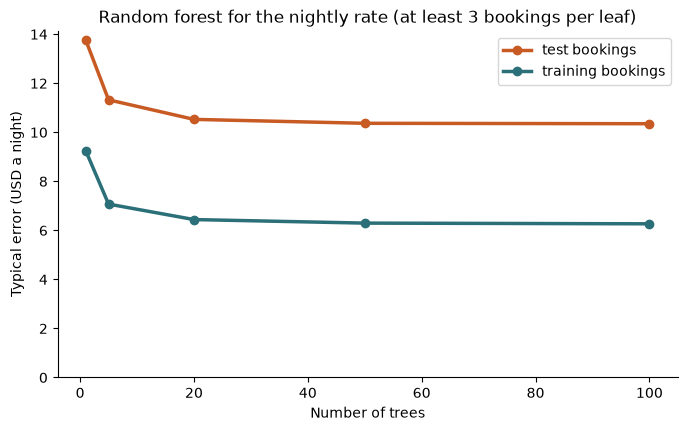

In [3]:
sizes = [1, 5, 20, 50, 100]
train_err, test_err = [], []
for n in sizes:
    f = model(RandomForestRegressor(n_estimators=n, min_samples_leaf=MIN_LEAF, random_state=42)).fit(Xr_train, yr_train)
    train_err.append(mean_absolute_error(yr_train, f.predict(Xr_train)))
    test_err.append(mean_absolute_error(yr_test, f.predict(Xr_test)))
plt.plot(sizes, test_err, marker="o", lw=2.5, color="#c85a24", label="test bookings")
plt.plot(sizes, train_err, marker="o", lw=2.5, color="#2b6f78", label="training bookings")
plt.title(f"Random forest for the nightly rate (at least {MIN_LEAF} bookings per leaf)")
plt.xlabel("Number of trees")
plt.ylabel("Typical error (USD a night)")
plt.ylim(0, None)
plt.legend()
plt.show()

**Think about it.** As you add trees, does the test error ever go up? Now try `MIN_LEAF = 1`, then `20`, and rerun both cells. What happens to the **gap** between training and test error?

<details><summary>Show the answer</summary>

With 3 bookings per leaf the test error falls from about USD 13.8 (one tree) to USD 10.5 (20 trees), then **flattens**: more trees never make a forest overfit, they only cost time. With `MIN_LEAF = 1` trees memorize bookings: training error drops to about USD 4, test stays at USD 10.4, a gap that buys nothing. With `20` the rules get too broad and both errors rise (test about USD 12.9). A leaf of about 3 and 100–200 trees is sensible.
</details>

## <span class="hz-step-n">02</span> Task 2 · Boosting: learning rate and number of trees

Boosting's two key settings work together: the **learning rate** (how much of each tree's correction is added) and the **number of trees** (`MAX_ITER`). Replay the idea in the simulator first, then try it on all bookings.

<div class="hz-widget" data-widget="boosting-steps">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_6_Live/">open this session on the course website</a> to use it.</p>
</div>

The cell trains boosting with your settings and draws its typical error on training and test bookings after each tree.

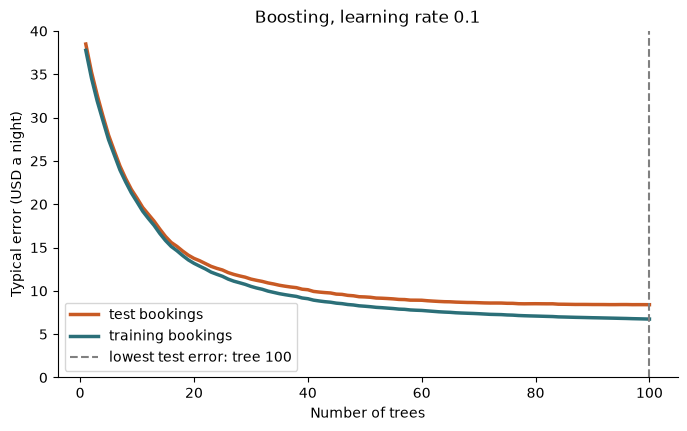

After 100 trees: training USD 6.7, test USD 8.4. Best test error USD 8.4 at tree 100.


In [4]:
# ✏️ Change these settings
LEARNING_RATE = 0.1
MAX_ITER = 100

b = model(HistGradientBoostingRegressor(learning_rate=LEARNING_RATE, max_iter=MAX_ITER, random_state=42)).fit(Xr_train, yr_train)
train_curve = [mean_absolute_error(yr_train, p) for p in b[-1].staged_predict(b[:-1].transform(Xr_train))]
test_curve = [mean_absolute_error(yr_test, p) for p in b[-1].staged_predict(b[:-1].transform(Xr_test))]
best = int(np.argmin(test_curve)) + 1
plt.plot(range(1, len(test_curve) + 1), test_curve, lw=2.5, color="#c85a24", label="test bookings")
plt.plot(range(1, len(train_curve) + 1), train_curve, lw=2.5, color="#2b6f78", label="training bookings")
plt.axvline(best, color="grey", ls="--", label=f"lowest test error: tree {best}")
plt.title(f"Boosting, learning rate {LEARNING_RATE}")
plt.xlabel("Number of trees")
plt.ylabel("Typical error (USD a night)")
plt.ylim(0, 40)
plt.legend()
plt.show()
print(f"After {len(test_curve)} trees: training USD {train_curve[-1]:.1f}, test USD {test_curve[-1]:.1f}. "
      f"Best test error USD {min(test_curve):.1f} at tree {best}.")

**Think about it.** Try `LEARNING_RATE = 0.5` with `MAX_ITER = 300`, then `0.02` with `300`. Where is the best test error, and what does the training error do? Is "more trees" always better?

<details><summary>Show the answer</summary>

With **0.5** the training error keeps falling (to about USD 1.8) but the test error is lowest at tree 20 (USD 9.3) and then rises to USD 10.3: the later trees learn noise, which is overfitting. With **0.02** it is still improving after 300 trees (USD 8.9): steps too small. With **0.1** and 300 trees, the best is about USD 8.4 at tree 118, and it barely moves after that. Unlike in a forest, more trees is *not* always better in boosting.
</details>

## <span class="hz-step-n">03</span> Task 3 · Choose a model for each question

The scoreboard is one input to the decision, not the decision. Weigh four criteria:

- **Accuracy** on the test bookings, in the metric that fits the decision.
- **Stability:** does the model change its answers when the history changes a little?
- **Explainability:** can you explain a single prediction to the person it affects?
- **Cost of errors:** what does one mistake cost Altamar, and how many decisions does the model make?

The cell trains the four models for each question (the line and tree exactly as in week 5) on the same training bookings, and times them.

In [5]:
recipes = {
    "rate": {"Linear": model(LinearRegression(), month_as_category=True),
             "Tree": model(DecisionTreeRegressor(max_depth=10, random_state=42)),    # week 5's tuned trees
             "Forest": model(RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=42)),
             "Boosting": model(HistGradientBoostingRegressor(random_state=42))},
    "cancel": {"Linear": model(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
               "Tree": model(DecisionTreeClassifier(max_depth=4, random_state=42)),
               "Forest": model(RandomForestClassifier(n_estimators=200, min_samples_leaf=3, random_state=42)),
               "Boosting": model(HistGradientBoostingClassifier(random_state=42))},
}
board = []
for question, models in recipes.items():
    X_tr, y_tr = (Xr_train, yr_train) if question == "rate" else (Xc_train, yc_train)
    for name, m in models.items():
        start = time.time()
        m.fit(X_tr, y_tr)
        seconds = time.time() - start
        score = rate_scores(name, m)["typical error (USD)"] if question == "rate" else cancel_scores(name, m)["AUC"]
        board.append({"question": question, "model": name, "accuracy": score, "seconds": round(seconds, 2)})
board = pd.DataFrame(board)
print(board.to_string(index=False, float_format=lambda v: f"{v:g}"))
print("\nAccuracy = typical error in USD for the rate (lower is better), AUC for cancellations (higher is better).")

question    model  accuracy  seconds
    rate   Linear      20.5     0.01
    rate     Tree      13.3     0.02
    rate   Forest      10.3      1.6
    rate Boosting       8.4     1.04
  cancel   Linear     0.739     0.01
  cancel     Tree     0.752     0.01
  cancel   Forest     0.771     0.55
  cancel Boosting      0.77     0.69

Accuracy = typical error in USD for the rate (lower is better), AUC for cancellations (higher is better).


**Stability.** The cell retrains each model on three different halves of the training bookings and measures how much their predictions for the same test bookings disagree (rate: USD; cancellations: percentage points).

In [6]:
halves = {"rate": [Xr_train.sample(frac=0.5, random_state=s).index for s in [1, 2, 3]],
          "cancel": [Xc_train.sample(frac=0.5, random_state=s).index for s in [1, 2, 3]]}
spread = []
for question, models in recipes.items():
    X_tr, y_tr, X_te = (Xr_train, yr_train, Xr_test) if question == "rate" else (Xc_train, yc_train, Xc_test)
    for name, m in models.items():
        preds = []
        for idx in halves[question]:
            copy = clone(m).fit(X_tr.loc[idx], y_tr.loc[idx])          # a fresh copy: the trained model stays as it is
            preds.append(copy.predict(X_te) if question == "rate" else 100 * copy.predict_proba(X_te)[:, 1])
        spread.append(np.ptp(np.array(preds), axis=0).mean().round(1))
board["disagreement"] = spread
print(board[["question", "model", "accuracy", "disagreement"]].to_string(index=False, float_format=lambda v: f"{v:g}"))

question    model  accuracy  disagreement
    rate   Linear      20.5           4.1
    rate     Tree      13.3          19.9
    rate   Forest      10.3           8.4
    rate Boosting       8.4           7.6
  cancel   Linear     0.739           5.4
  cancel     Tree     0.752          13.9
  cancel   Forest     0.771           8.4
  cancel Boosting      0.77          17.6


**A decision scorecard.** Managers often compare options with weighted criteria. The cell turns each criterion into a score from 1 (worst of the four) to 5 (best), using the numbers above and a fixed explainability rating (line 5, tree 4, forest and boosting 2). Set the weights to what matters for *your* decision.

In [7]:
# ✏️ Change these settings
QUESTION = "rate"                      # "rate" or "cancel"
WEIGHTS = {"accuracy": 0.5, "stability": 0.2, "explainability": 0.2, "speed": 0.1}

card = board[board["question"] == QUESTION].set_index("model")
def to_1_5(values, higher_is_better):
    v = values if higher_is_better else -values
    return (1 + 4 * (v - v.min()) / (v.max() - v.min())).round(1)
scores = pd.DataFrame({
    "accuracy": to_1_5(card["accuracy"], higher_is_better=(QUESTION == "cancel")),
    "stability": to_1_5(card["disagreement"], higher_is_better=False),
    "explainability": pd.Series({"Linear": 5, "Tree": 4, "Forest": 2, "Boosting": 2}),
    "speed": to_1_5(card["seconds"], higher_is_better=False),
})
scores["weighted score"] = sum(scores[k] * w for k, w in WEIGHTS.items()).div(sum(WEIGHTS.values())).round(2)
print(scores.sort_values("weighted score", ascending=False))

          accuracy  stability  explainability  speed  weighted score
Boosting       5.0        4.1               2    2.4            3.96
Forest         4.4        3.9               2    1.0            3.48
Tree           3.4        1.0               4    5.0            3.20
Linear         1.0        5.0               5    5.0            3.00


**Think about it.** With the default weights, which model wins each question? What weights make the **line** win the rate question, and what decision would justify them? Then write two sentences per question (*"For the rate we choose … because …"*) covering all four criteria.

<details><summary>Show the answer</summary>

Boosting wins the rate: USD 8.4 vs 20.5 outweighs its lower explainability. The line wins only if explainability weighs far more, e.g. when each rate must be justified to a client. For cancellations the **forest** wins: as accurate as boosting, and much steadier (boosting's risks move about 18 points between samples, the forest's about 8). Example: *"For cancellations, the forest: AUC 0.77, 123 real cancellations among the 150 riskiest bookings (92 for the logistic model), and stable."*
</details>

## <span class="hz-step-n">04</span> Task 4 · Partial dependence for an input of your choice

Partial dependence answers "how does the prediction change with this input, all else equal?". The simulator shows lead time and month; now pick another input. Some worth trying: `nights`, `weekend_nights`, `adults` and `children` for the rate; `special_requests`, `adr` (the rate itself) and `previous_cancellations` for cancellations; `channel` for either.

<div class="hz-widget" data-widget="partial-dependence">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_6_Live/">open this session on the course website</a> to use it.</p>
</div>

The cell draws the partial dependence of your input, one line per hotel, using the boosting models trained in Task 3.

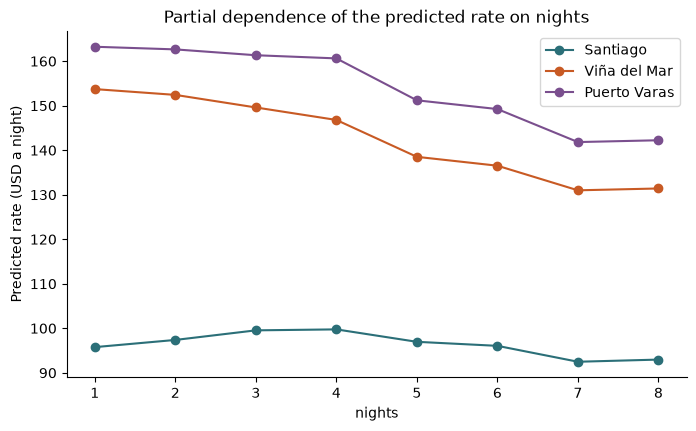

In [8]:
# ✏️ Change these settings
QUESTION = "rate"                      # "rate" or "cancel"
INPUT = "nights"                       # any column except "hotel"; "adr" only for "cancel"

m, X_test = (recipes["rate"]["Boosting"], Xr_test) if QUESTION == "rate" else (recipes["cancel"]["Boosting"], Xc_test)
column = X_test[INPUT]
if column.dtype == object or column.nunique() <= 15:
    grid = sorted(column.unique())
else:
    grid = sorted(set(np.percentile(column, np.linspace(1, 99, 20)).round(0)))
for h in HOTELS:
    values = pd_curve(m, X_test[X_test["hotel"] == h], INPUT, grid, proba=(QUESTION == "cancel"))
    plt.plot([str(g) for g in grid] if column.dtype == object else grid,
             values * (100 if QUESTION == "cancel" else 1), marker="o", color=COLORS[h], label=h)
plt.title(f"Partial dependence of the {'predicted rate' if QUESTION == 'rate' else 'cancellation risk'} on {INPUT}")
plt.xlabel(INPUT)
plt.ylabel("Predicted rate (USD a night)" if QUESTION == "rate" else "Predicted chance of cancelling (%)")
plt.legend()
plt.show()

**Think about it.** Describe the shape in one business sentence. A line, a step, a hump? Would a straight line capture it? Name one reason why it shows **association, not cause**.

<details><summary>Show the answer</summary>

For `nights` and the rate you should see **steps down** at 5 and 7 nights: Altamar's long-stay discounts, which a line would blur into a gentle slope. For `special_requests` and cancellations the risk **falls** with each request: guests who ask for a crib or a high floor are committed. Association, not cause: adding requests would not make a guest come. Requests reveal commitment; they do not create it.
</details>

## <span class="hz-step-n">05</span> Task 5 · Draft the pyramid for Altamar's management

The general manager has ten minutes. Lead with the recommendation, support it with three arguments, and put one piece of evidence (a chart or a number) under each. Replay the pyramid in the simulator, then fix the weak draft in the next cell: it is written in report order, the way most first drafts are.

<div class="hz-widget" data-widget="pyramid">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_6_Live/">open this session on the course website</a> to use it.</p>
</div>

The cell checks your pyramid against five rules and prints it as an outline. Rewrite the three settings until every rule passes.

In [9]:
# ✏️ Change these settings
KEY_MESSAGE = "We tested four models on Altamar's bookings."
ARGUMENTS = {
    "Methodology": ["Train/test split, 75% / 25%"],
    "Gradient boosting has the best R²": ["R² 0.96 vs 0.74 for the line"],
    "Lead time is the most important input for cancellations": [],
}

ACTIONS = ("use", "price", "oversell", "review", "raise", "cut", "adopt", "set", "launch", "stop", "start", "invest", "require")
checks = [
    ("The key message is one short sentence (30 words or fewer)", len(KEY_MESSAGE.split()) <= 30),
    ("The key message recommends an action", any(w.strip(".,:;").lower() in ACTIONS for w in KEY_MESSAGE.split())),
    ("The key message has a number", any(ch.isdigit() for ch in KEY_MESSAGE)),
    ("There are exactly three arguments", len(ARGUMENTS) == 3),
    ("Every argument has 1 to 3 pieces of evidence, and none is about method",
     all(1 <= len(ev) <= 3 for ev in ARGUMENTS.values()) and not any("method" in a.lower() for a in ARGUMENTS)),
]
for rule, ok in checks:
    print(("✔ " if ok else "✘ ") + rule)
print("\n" + KEY_MESSAGE)
for i, (arg, evidence) in enumerate(ARGUMENTS.items(), start=1):
    print(f"  {i}. {arg}")
    for ev in evidence:
        print(f"       – {ev}")

✔ The key message is one short sentence (30 words or fewer)
✘ The key message recommends an action
✘ The key message has a number
✔ There are exactly three arguments
✘ Every argument has 1 to 3 pieces of evidence, and none is about method

We tested four models on Altamar's bookings.
  1. Methodology
       – Train/test split, 75% / 25%
  2. Gradient boosting has the best R²
       – R² 0.96 vs 0.74 for the line
  3. Lead time is the most important input for cancellations


**Think about it.** Which rules did the draft break, and why does each matter to a manager with ten minutes? Rewrite it.

<details><summary>Show the answer</summary>

It opens with what *we did*, not what *they should do*; one argument is method (appendix material); one has no evidence. A passing version:

- **Key message:** "Use gradient boosting to price: it cuts the typical pricing error from USD 20 to USD 8 a night."
- **1. It prices like our best revenue manager:** R² 0.96 vs 0.74 for the line and 0.89 for week 5's tree.
- **2. We know what drives it:** month, room and hotel; each hotel's own seasons.
- **3. It pays off:** 11% of bookings sold more than 10% below similar ones, about USD 18,000 a year.
</details>

**Before the quiz.** Your team now does the same for its case: run the comparison and explanation sections of the [case toolkit](https://hizocar.github.io/mba-business-analytics-1/case/Case_Toolkit/), choose a model with reasons, and build the 10-slide pyramid described in the [live session](https://hizocar.github.io/mba-business-analytics-1/sessions/Session_6_Live/). The hand-in is due one week after this session; see the [rubric](https://hizocar.github.io/mba-business-analytics-1/case/case/).

## Graded quiz

Five questions on this week's ideas. They count for **5% of the module grade**, and **only your first submission counts**, so finish the lab before you start. Use the name and email you are registered with in the program.

<div class="hz-widget" data-widget="graded-quiz">
<script type="application/json">{"id": "session-6", "title": "Week 6 quiz", "questions": [{"q": "Your forest's typical test error is USD 10.7 with 100 trees and USD 10.6 with 300 trees. What should you do?", "options": ["Remove the leaf-size limit so that each tree learns more", "Switch to a single deeper tree, which is faster and just as accurate", "Use 300 trees and keep adding more, since more trees always help", "Keep 100 trees: the extra trees barely help and take three times as long to train and run"]}, {"q": "With learning rate 0.5 and 300 trees, boosting's training error keeps falling, but its test error is lowest at tree 24 and then rises. What is happening?", "options": ["The model is underfitting and needs more trees", "The test bookings changed during training", "The later trees are fitting noise in the training bookings: the model is overfitting", "After tree 24, boosting turns into a random forest"]}, {"q": "Permutation importance of the deposit type is about zero in the rate model but among the largest in the cancellation model. What do you tell management?", "options": ["The rate model is broken because it ignores the deposit", "Deposit policy does not matter to Altamar", "The deposit type barely changes what a booking pays, but it is a strong signal of whether it will be cancelled", "Deposits cause guests to keep their bookings, so require one on every booking"]}, {"q": "Partial dependence for Puerto Varas shows a predicted rate of USD 197 in January, USD 168 in July and USD 108 in May. Which reading is correct?", "options": ["Guests pay more in January because they book earlier", "The month matters for Puerto Varas only", "Raising May rates to USD 197 would earn as much as January does", "For otherwise identical bookings, the model quotes much more in January and July than in May"]}, {"q": "The first slide of a team's deck reads: 'Methodology: data cleaning, train/test split, four models'. What is the best fix under the pyramid principle?", "options": ["Keep it: management must understand the method before the result", "Add the full metrics table to the same slide", "Replace it with the recommendation and its key number, e.g. 'Price with boosting: the typical error falls from USD 20 to USD 8 a night'", "Keep it, but put an agenda slide before it"]}]}</script>
</div>